# WPBC Feature Selection Using Reinforcement Learning — Replication

**Based on:** Rasoul, Adewole, and Akakpo, *Feature Selection Using Reinforcement Learning* (2021), arXiv:2101.09460.

**Dataset:** Wisconsin Prognostic Breast Cancer (WPBC), obtained from the UCI Machine Learning Repository.

## Objective

The objective of this experiment is to study how Reinforcement Learning (RL) can be applied to feature selection. Instead of using every available feature, the agent explores different subsets of features and learns which feature additions produce improvements in classification performance.

A Support Vector Machine (SVM) with an RBF kernel is used to evaluate the selected feature subsets.

## Methodology

This notebook implements a paper-informed version of the proposed approach. It represents feature selection as a Markov Decision Process (MDP), uses Temporal Difference learning (TD(0)) to update state values, and maintains a global Average of Reward (AOR) score for each feature.

The implementation also compares RL-based feature selection with several filter-based feature-ranking methods.

## Important limitations

This is a **paper-informed reproduction, not a bit-for-bit replication**. Some implementation details are not fully specified in the original paper. The WPBC dataset is small and imbalanced, and its reported accuracy of 76.29% is close to the majority-class baseline. Consequently, accuracy alone is insufficient to establish that the RL method is effective.

The results should be interpreted as an experimental study of feature selection, not as evidence for clinical use.

## 1. Install and import

## 1. Install and Import Required Libraries

This section installs and imports the libraries required for dataset handling, data visualization, machine learning, and reinforcement learning.

- **NumPy and Pandas:** Numerical computation and data manipulation.
- **Matplotlib and Seaborn:** Exploratory data visualization.
- **Scikit-learn:** Data preprocessing, cross-validation, classification, feature ranking, and model evaluation.
- **UCI ML Repository client:** Downloading the WPBC dataset.

The experiment uses an RBF-kernel Support Vector Machine as the classifier for evaluating feature subsets.

In [ ]:
!pip -q install ucimlrepo

In [ ]:
import random, time, warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay
)
from sklearn.feature_selection import mutual_info_classif, f_classif, chi2
from sklearn.ensemble import RandomForestClassifier

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
plt.rcParams["figure.figsize"] = (9, 5)

## 2. Download and inspect WPBC from UCI

## 2. Download and Inspect the WPBC Dataset

The Wisconsin Prognostic Breast Cancer (WPBC) dataset is obtained from the UCI Machine Learning Repository.

The dataset contains patient-related measurements and a target representing the recurrence outcome. Before applying feature selection, the dataset is inspected to understand its structure, column names, data types, missing values, and target distribution.

Identifier and time-related columns are excluded from the model inputs so that the feature-selection experiment focuses on the remaining predictive variables.

This preliminary inspection also helps identify class imbalance and potential data-quality issues before model training.

In [ ]:
wpbc = fetch_ucirepo(id=16)
X_raw = wpbc.data.features.copy()
y_raw = wpbc.data.targets.copy()

print("Dataset:", wpbc.metadata.get("name"))
print("Raw feature shape:", X_raw.shape, "| target shape:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())
print("Feature columns:", list(X_raw.columns))
print("Target columns:", list(y_raw.columns))

Dataset: Breast Cancer Wisconsin (Prognostic)
Raw feature shape: (198, 33) | target shape: (198, 1)


,Time,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,tumor_size,lymph_node_status
0,31,18.02,27.60,117.50,1013.0,0.09489,0.1036,0.1086,0.07055,0.1865,...,139.70,1436.0,0.1195,0.1926,0.3140,0.1170,0.2677,0.08113,5.0,5.0
1,61,17.99,10.38,122.80,1001.0,0.11840,0.2776,0.3001,0.14710,0.2419,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,3.0,2.0
2,116,21.37,17.44,137.50,1373.0,0.08836,0.1189,0.1255,0.08180,0.2333,...,159.10,1949.0,0.1188,0.3449,0.3414,0.2032,0.4334,0.09067,2.5,0.0
3,123,11.42,20.38,77.58,386.1,0.14250,0.2839,0.2414,0.10520,0.2597,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,2.0,0.0
4,27,20.29,14.34,135.10,1297.0,0.10030,0.1328,0.1980,0.10430,0.1809,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,3.5,0.0


,Outcome
0,N
1,N
2,N
3,N
4,R


Feature columns: ['Time', 'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'tumor_size', 'lymph_node_status']
Target columns: ['Outcome']


In [ ]:
target_col = y_raw.columns[0]
y_text = y_raw[target_col].astype(str).str.strip()
print("Class counts:")
display(y_text.value_counts().to_frame("count"))

# Exclude ID and follow-up Time from predictors to avoid ID leakage and
# using follow-up duration as a predictor of recurrence status.
drop_cols = [c for c in X_raw.columns if c.strip().lower() in {"id", "time"}]
X = X_raw.drop(columns=drop_cols, errors="ignore").copy()
for c in X.columns:
    X[c] = pd.to_numeric(X[c], errors="coerce")

encoder = LabelEncoder()
y = pd.Series(encoder.fit_transform(y_text), index=y_text.index, name="target")
class_names = list(encoder.classes_)
print("Excluded predictor columns:", drop_cols)
print("Model input feature count:", X.shape[1])
print("Class encoding:", {str(k): int(encoder.transform([k])[0]) for k in class_names})
print("Missing values total:", int(X.isna().sum().sum()))

Class counts:


,count
Outcome,
N,151
R,47


Excluded predictor columns: ['Time']
Model input feature count: 32
Class encoding: {'N': 0, 'R': 1}
Missing values total: 4


## 3. Exploratory Data Visualization

Exploratory data analysis is performed to understand the characteristics of the WPBC dataset before applying the feature-selection algorithm.

The visualizations help examine:

- The distribution of the target classes.
- The distribution and variability of selected numerical features.
- Potential differences in the dataset's characteristics.

These plots provide context for interpreting the model results. In particular, the target distribution is important because an imbalanced dataset can produce high classification accuracy even when the minority class is predicted poorly.

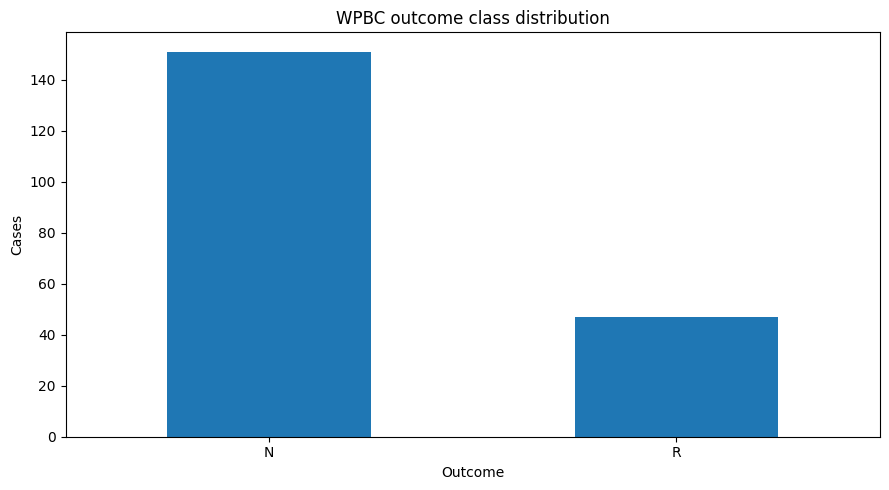

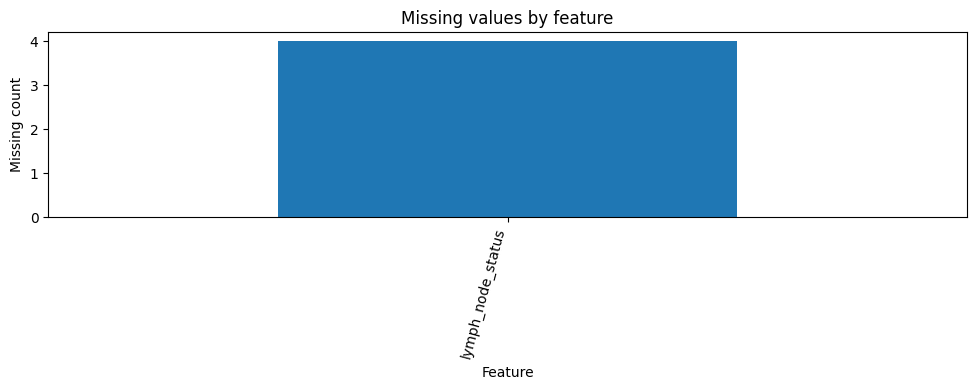

In [ ]:
plt.figure()
y_text.value_counts().reindex(class_names).plot(kind="bar")
plt.title("WPBC outcome class distribution")
plt.xlabel("Outcome"); plt.ylabel("Cases"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

missing = X.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if len(missing):
    plt.figure(figsize=(10, 4))
    missing.plot(kind="bar")
    plt.title("Missing values by feature")
    plt.xlabel("Feature"); plt.ylabel("Missing count")
    plt.xticks(rotation=75, ha="right"); plt.tight_layout(); plt.show()
else:
    print("No missing predictor values found.")

## 4. Split the Dataset

The dataset is divided into training, validation, and test partitions using stratified sampling.

- **Training set — 60%:** Used for model development and cross-validation-based reward estimation.
- **Validation set — 20%:** Used to compare discovered feature subsets and select feature counts for the baseline methods.
- **Test set — 20%:** Reserved for the final evaluation of the selected approaches.

Stratification maintains approximately the same target-class proportions across the three partitions.

The test set is not used to calculate RL rewards or select feature subsets. This separation helps reduce data leakage and provides a more reliable estimate of performance on unseen data.

Because the dataset is small, the random seed and split proportions should be reported when presenting the results.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
feature_names = list(X.columns)
n_features = len(feature_names)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")
print("Train class counts:", y_train.value_counts().to_dict())
print("Validation class counts:", y_val.value_counts().to_dict())
print("Test class counts:", y_test.value_counts().to_dict())

Train: 118 | Validation: 40 | Test: 40
Train class counts: {0: 90, 1: 28}
Validation class counts: {0: 30, 1: 10}
Test class counts: {0: 31, 1: 9}


## 5. SVM Evaluator and Baseline Performance

A Support Vector Machine (SVM) with an RBF kernel is used as the classification model throughout the experiment.

The model is combined with preprocessing steps that handle missing values through median imputation and standardize numerical features. These steps are fitted within the relevant training procedure to avoid using validation or test information during preprocessing.

The classifier evaluates the predictive performance of different feature subsets. A majority-class baseline is also calculated to establish the performance that can be achieved by always predicting the most frequent class.

The majority-class baseline is particularly important for WPBC because the target classes are imbalanced. Any feature-selection method should be evaluated against this baseline rather than judged by accuracy alone.

,model,n_features,accuracy,balanced_accuracy,recurrence_precision,recurrence_recall,recurrence_f1
0,Majority-class baseline (validation),0,0.75,0.5,0.0,0.0,0.0
1,SVM all features (validation),32,0.75,0.5,0.0,0.0,0.0


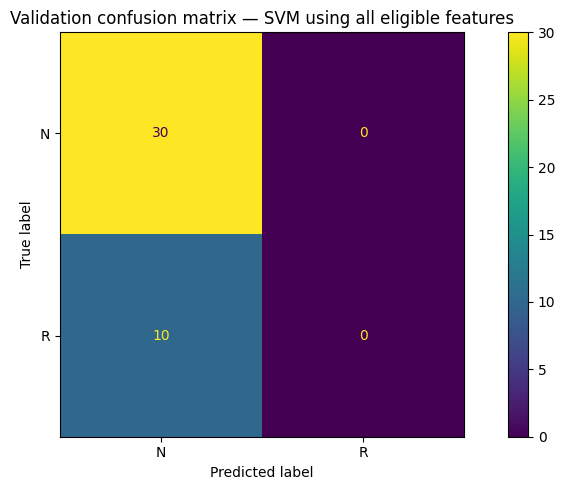

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

def make_svm():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
    ])

# Train-only CV is the RL reward signal. Validation is not used to calculate rewards.
REWARD_FOLDS = 5
reward_cv = StratifiedKFold(n_splits=REWARD_FOLDS, shuffle=True, random_state=SEED)
reward_cache = {}

def cv_score_state(feature_indices):
    key = tuple(sorted(feature_indices))
    if key not in reward_cache:
        features = [feature_names[i] for i in key]
        if not features:
            reward_cache[key] = float(y_train.value_counts(normalize=True).max())
        else:
            scores = cross_val_score(
                make_svm(), X_train[features], y_train,
                cv=reward_cv, scoring="accuracy", n_jobs=1
            )
            reward_cache[key] = float(np.mean(scores))
    return reward_cache[key]

def fit_predict(features, X_fit=X_train, y_fit=y_train, X_eval=X_val):
    model = make_svm()
    model.fit(X_fit[features], y_fit)
    return model.predict(X_eval[features]), model

all_pred, all_model = fit_predict(feature_names)
majority_label = int(y_train.value_counts().idxmax())
majority_pred = np.full(len(y_val), majority_label)

def metric_row(name, y_true, pred, n_feat):
    positive_label = encoder.transform(["R"])[0] if "R" in class_names else 1
    return {
        "model": name,
        "n_features": n_feat,
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "recurrence_precision": precision_score(y_true, pred, pos_label=positive_label, zero_division=0),
        "recurrence_recall": recall_score(y_true, pred, pos_label=positive_label, zero_division=0),
        "recurrence_f1": f1_score(y_true, pred, pos_label=positive_label, zero_division=0)
    }

baseline_table = pd.DataFrame([
    metric_row("Majority-class baseline (validation)", y_val, majority_pred, 0),
    metric_row("SVM all features (validation)", y_val, all_pred, n_features)
])
display(baseline_table.round(3))
ConfusionMatrixDisplay.from_predictions(y_val, all_pred, display_labels=class_names)
plt.title("Validation confusion matrix — SVM using all eligible features")
plt.tight_layout(); plt.show()

## 6. Reinforcement Learning Algorithm

Feature selection is represented as a Markov Decision Process (MDP).

### State representation

A state is a subset of selected feature indices. For example, a state containing features 2 and 5 represents a model trained using those two features.

### Action representation

An action adds one feature that has not already been selected. The next state is the current subset with the selected feature added.

### Reward function

The reward is the change in **train-CV accuracy** between the current subset and the subset obtained after adding a feature. Positive rewards indicate an improvement in cross-validated accuracy, while negative rewards indicate a decrease.

### TD(0) state-value update

Temporal Difference learning updates the estimated value of a state using the observed reward and the estimated value of the next state:

\[
V(s)\leftarrow V(s)+\alpha
\left[r+\gamma V(s')-V(s)\right]
\]

Here, \(V(s)\) is the estimated value of the current state, \(\alpha\) is the learning rate, \(\gamma\) is the discount factor, \(r\) is the observed reward, and \(s'\) is the next state.

### Global Average of Reward (AOR)

The algorithm maintains one global AOR score for each feature. Whenever a feature is added, its reward contributes to the running average associated with that feature. These scores are later used to construct a feature ranking.

### Exploration and exploitation

The agent starts from random non-empty subsets containing 1–5 features. For previously unseen states, it selects a feature randomly. For visited states, an epsilon-based exploration strategy balances random exploration with selecting a feature that has a high global AOR score.

A cache stores previously calculated subset scores to avoid unnecessary repeated SVM evaluations.

This implementation follows the central ideas of the paper while making some choices explicit where the original description is underspecified.

In [ ]:
ALPHA = 0.10
GAMMA = 0.90
N_EPISODES = 180
DEFAULT_EPSILON = 0.50

def run_rl(epsilon=DEFAULT_EPSILON, episodes=N_EPISODES, seed=SEED, start_min=1, start_max=5):
    rng = random.Random(seed)
    state_value = defaultdict(float)
    state_visits = defaultdict(int)
    global_aor = np.zeros(n_features, dtype=float)
    feature_counts = np.zeros(n_features, dtype=int)
    # Local cache refers to train-only 5-fold CV scores.
    local_score_cache = {}
    episode_max_values, episode_best_scores, unique_state_counts = [], [], []
    visited_subsets = set()
    best_cv_state = (float("-inf"), tuple())

    def score_state(state):
        state = tuple(sorted(state))
        if state not in local_score_cache:
            local_score_cache[state] = cv_score_state(state)
        return local_score_cache[state]

    for ep in range(episodes):
        start_size = rng.randint(start_min, min(start_max, n_features))
        state = tuple(sorted(rng.sample(range(n_features), start_size)))
        state_visits[state] += 1
        current_score = score_state(state)
        visited_subsets.add(state)
        if current_score > best_cv_state[0]:
            best_cv_state = (current_score, state)
        best_score_episode = current_score
        episode_values = [state_value[state]]

        while len(state) < n_features:
            available = [f for f in range(n_features) if f not in state]
            if state_visits[state] <= 1 or rng.random() < epsilon:
                action = rng.choice(available)
            else:
                untried = [f for f in available if feature_counts[f] == 0]
                action = rng.choice(untried) if untried else max(available, key=lambda f: global_aor[f])

            next_state = tuple(sorted(state + (action,)))
            next_score = score_state(next_state)
            reward = next_score - current_score

            state_value[state] += ALPHA * (
                reward + GAMMA * state_value[next_state] - state_value[state]
            )
            feature_counts[action] += 1
            k_count = feature_counts[action]
            global_aor[action] += (reward - global_aor[action]) / k_count

            state = next_state
            current_score = next_score
            state_visits[state] += 1
            visited_subsets.add(state)
            episode_values.append(state_value[state])
            best_score_episode = max(best_score_episode, next_score)
            if next_score > best_cv_state[0]:
                best_cv_state = (next_score, next_state)

        episode_max_values.append(max(episode_values) if episode_values else 0.0)
        episode_best_scores.append(best_score_episode)
        unique_state_counts.append(len(state_visits))

    return {
        "epsilon": epsilon, "state_value": state_value, "state_visits": state_visits,
        "global_aor": global_aor, "feature_counts": feature_counts,
        "score_cache": local_score_cache, "episode_max_values": episode_max_values,
        "episode_best_scores": episode_best_scores, "unique_state_counts": unique_state_counts,
        "visited_subsets": visited_subsets, "best_cv_state": best_cv_state
    }

start = time.time()
rl = run_rl()
print(f"RL run completed in {time.time()-start:.1f}s")
print("Unique states:", len(rl["state_visits"]), "| cached subset evaluations:", len(rl["score_cache"]))
print("Best state by train-CV accuracy:", rl["best_cv_state"])

RL run completed in 226.4s
Unique states: 5031 | cached subset evaluations: 5031
Best state by train-CV accuracy: (0.7884057971014492, (0, 11, 26, 31))


## 7. Paper-Style Figure 1: Maximum State Value per Episode

This section visualizes the maximum state value recorded during each RL episode.

The plot helps examine how the value estimates evolve as the agent explores different feature subsets. Changes in the curve may indicate that the agent has encountered states with different estimated values.

The maximum value is recorded separately for each episode rather than as a cumulative maximum over all previous episodes. Therefore, the graph represents the values observed during individual episodes.

The curve should be interpreted as a learning diagnostic, not as proof that the agent has found the globally optimal feature subset.

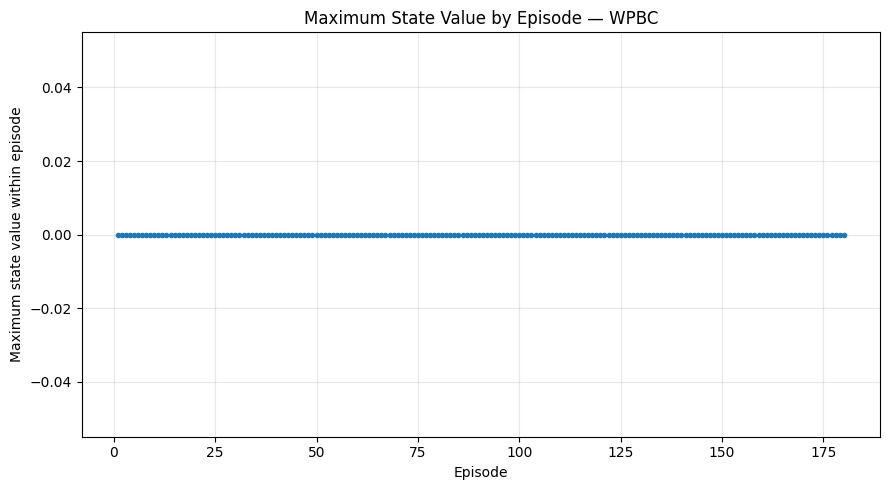

In [ ]:
plt.figure()
plt.plot(range(1, len(rl["episode_max_values"])+1), rl["episode_max_values"], marker=".")
plt.title("Maximum State Value by Episode — WPBC")
plt.xlabel("Episode"); plt.ylabel("Maximum state value within episode")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 8. Paper-Style Figure 2: Effect of Epsilon on State Exploration

Epsilon controls the exploration component of the agent's feature-selection strategy.

- **Lower epsilon:** The agent relies more heavily on the learned global AOR scores.
- **Higher epsilon:** The agent explores more randomly and may visit a wider variety of feature subsets.

To study the effect of epsilon, the RL algorithm is rerun for each tested epsilon value. Each run performs its own learning process instead of reusing results from the main experiment.

The plot compares the number of unique states visited for different epsilon values. When multiple random seeds are used, the mean and standard deviation show how much the results vary across runs.

The sweep uses fewer episodes than the main experiment to control computation time. Consequently, the results describe exploration under the chosen experimental settings and should not be interpreted as universal behavior for every dataset or run length.

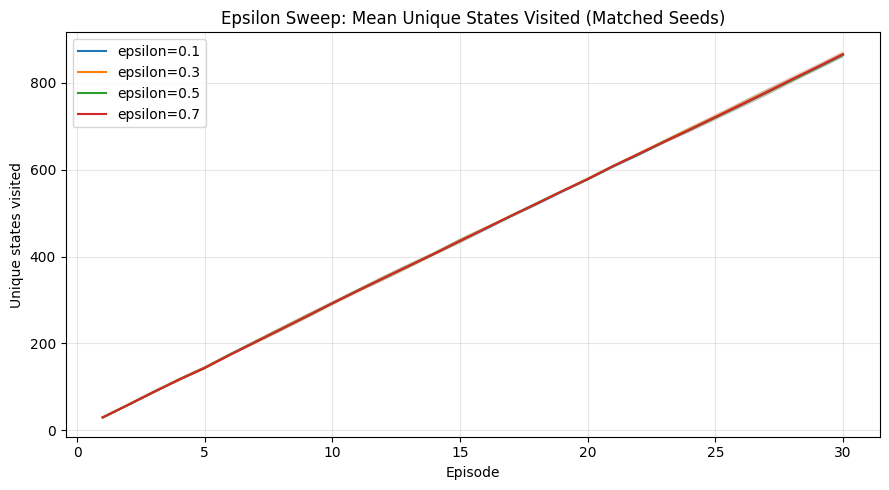

In [ ]:
SWEEP_EPISODES = 30
epsilon_values = [0.1, 0.3, 0.5, 0.7]
SWEEP_SEEDS = [101, 202, 303]
sweep_results = []

# Matched seeds: each epsilon is tested with the same seed set.
for eps in epsilon_values:
    for sd in SWEEP_SEEDS:
        run = run_rl(epsilon=eps, episodes=SWEEP_EPISODES, seed=sd)
        for episode, count in enumerate(run["unique_state_counts"], start=1):
            sweep_results.append({"epsilon": eps, "seed": sd, "episode": episode,
                                  "unique_states": count})

sweep_df = pd.DataFrame(sweep_results)
plt.figure()
for eps in epsilon_values:
    sub = sweep_df[sweep_df["epsilon"] == eps]
    summary = sub.groupby("episode")["unique_states"].agg(["mean", "std"]).reset_index()
    plt.plot(summary["episode"], summary["mean"], label=f"epsilon={eps}")
    plt.fill_between(summary["episode"],
                     summary["mean"] - summary["std"].fillna(0),
                     summary["mean"] + summary["std"].fillna(0), alpha=0.15)
plt.title("Epsilon Sweep: Mean Unique States Visited (Matched Seeds)")
plt.xlabel("Episode"); plt.ylabel("Unique states visited")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 9. Feature Ranking Using Global Average of Reward

After the RL training process, the global AOR score of each feature is used to construct a feature ranking.

Features with higher scores are ranked ahead of features with lower scores. A high AOR score indicates that adding the feature has tended to produce more favorable rewards in the states explored by the agent.

Features that were never selected do not have an observed AOR score. They are placed after features with observed scores so that unvisited features are not incorrectly treated as having a reward of zero.

The resulting ranking is used to investigate whether a smaller subset of highly ranked features can maintain classification performance.

The ranking is based on the agent's exploration history; it is not a guarantee of each feature's independent predictive importance or causal relevance.

,feature,global_AOR,times_selected
4,smoothness1,0.000808,169
7,concave_points1,0.000616,166
6,concavity1,0.000589,158
24,smoothness3,0.000569,151
3,area1,0.000513,164
29,fractal_dimension3,0.000506,167
26,concavity3,0.000477,161
13,area2,0.000444,173
0,radius1,0.000354,166
28,symmetry3,0.000319,168


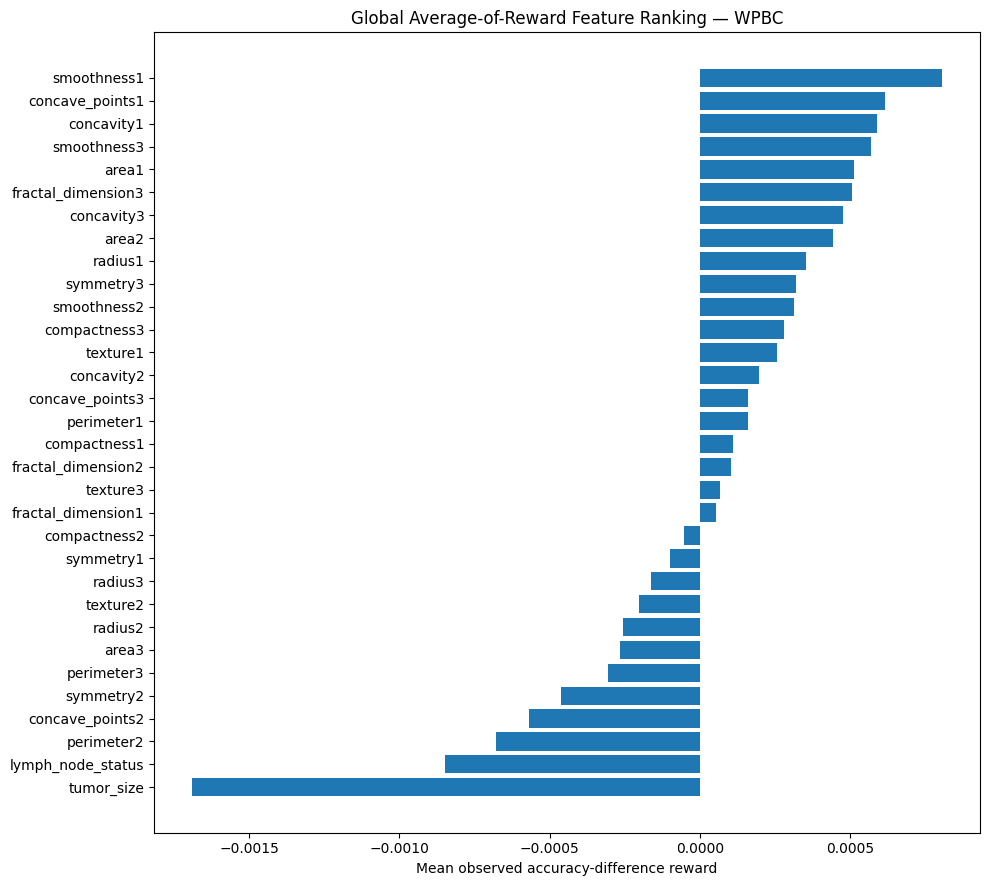

In [ ]:
aor_df = pd.DataFrame({
    "feature": feature_names,
    "global_AOR": np.where(rl["feature_counts"] > 0, rl["global_aor"], -np.inf),
    "times_selected": rl["feature_counts"]
}).sort_values("global_AOR", ascending=False)
display(aor_df)
plt.figure(figsize=(10, max(5, 0.28*n_features)))
p = aor_df.sort_values("global_AOR")
plt.barh(p["feature"], p["global_AOR"])
plt.title("Global Average-of-Reward Feature Ranking — WPBC")
plt.xlabel("Mean observed accuracy-difference reward")
plt.tight_layout(); plt.show()

## 10. Comparison with Baseline Feature-Selection Methods

The RL-based feature ranking is compared with several conventional feature-ranking methods.

The implemented baselines are:

1. **Chi-squared (Chi²):** Measures the association between non-negative feature values and the target.
2. **Mutual Information (MI):** Estimates the statistical dependence between a feature and the target. It is used here as an information-gain-style univariate score.
3. **ANOVA F-score:** Evaluates differences in feature values across target classes.
4. **Random Forest feature importance:** Uses feature-importance scores obtained from a Random Forest classifier.
5. **Relief-style score:** Uses an approximate Relief-style procedure to assess how well a feature distinguishes observations from different classes.
6. **Symmetrical Uncertainty (SU):** Uses a normalized information-theoretic measure to assess the association between a feature and the target.

The filter-based scores are fitted using the training partition only. Each method produces a feature ranking, from which subsets of different sizes are evaluated using the same SVM pipeline.

Validation performance is used to compare feature counts. The test set is kept separate until the final evaluation.

These methods use different scoring principles, so their rankings are not directly interchangeable in meaning. The comparison focuses on their resulting predictive performance under the same evaluation procedure.

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 31 are removed. Consider decreasing the number of bins.
  warnings.warn(


Added Relief-style and Symmetrical Uncertainty baselines.


method,ANOVA F-score,Chi-squared,Mutual information,RL global AOR,Random forest importance,Relief-style (approx.),Symmetrical uncertainty
n_features,,,,,,,
1,0.750,0.75,0.750,0.75,0.750,0.750,0.75
2,0.750,0.75,0.750,0.75,0.750,0.750,0.75
3,0.750,0.75,0.775,0.75,0.750,0.750,0.75
4,0.750,0.75,0.775,0.75,0.750,0.750,0.75
5,0.775,0.75,0.775,0.75,0.750,0.750,0.75
6,0.775,0.75,0.775,0.75,0.750,0.750,0.75
7,0.750,0.75,0.775,0.75,0.750,0.750,0.75
8,0.750,0.75,0.775,0.75,0.750,0.775,0.75
9,0.750,0.75,0.775,0.75,0.775,0.750,0.75


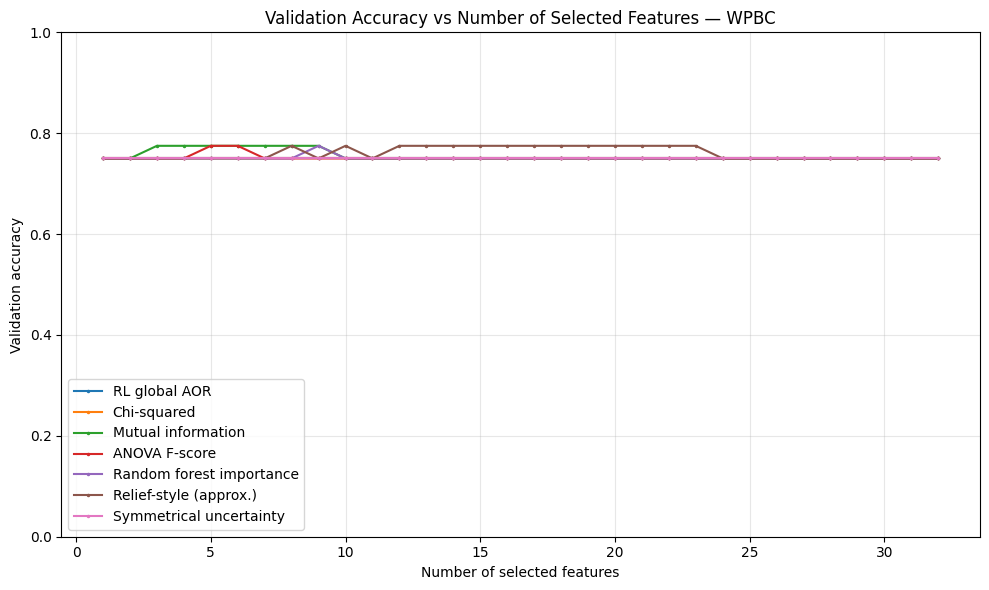

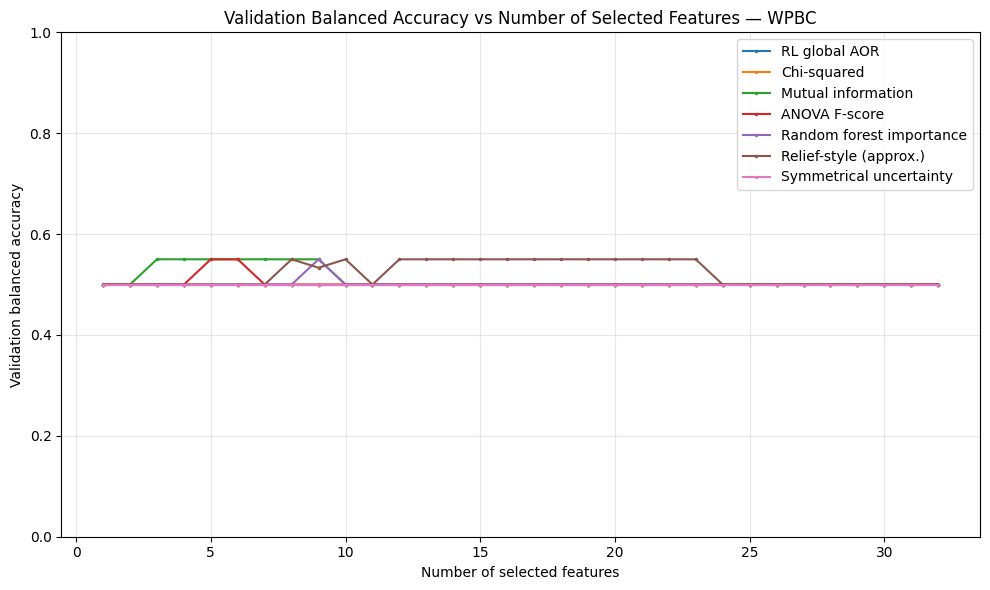

In [ ]:
# Impute using train only for filter calculations.
imp = SimpleImputer(strategy="median")
Xtr_imp = pd.DataFrame(imp.fit_transform(X_train), columns=feature_names, index=X_train.index)
ytr_arr = np.asarray(y_train)

# Chi-square requires non-negative features; min-max scale each feature using training data.
mm = MinMaxScaler()
Xtr_nonneg = pd.DataFrame(mm.fit_transform(Xtr_imp), columns=feature_names, index=X_train.index)
chi_scores, _ = chi2(Xtr_nonneg, y_train)
mi_scores = mutual_info_classif(Xtr_imp, y_train, random_state=SEED)
anova_scores, _ = f_classif(Xtr_imp, y_train)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, class_weight="balanced")
rf.fit(Xtr_imp, y_train)
rf_scores = rf.feature_importances_

def descending_order(scores):
    arr = np.nan_to_num(np.asarray(scores, dtype=float), nan=-np.inf, posinf=np.inf, neginf=-np.inf)
    return list(np.argsort(arr)[::-1])

rankings = {
    "RL global AOR": list(np.argsort(np.where(rl["feature_counts"] > 0, rl["global_aor"], -np.inf))[::-1]),
    "Chi-squared": descending_order(chi_scores),
    "Mutual information": descending_order(mi_scores),
    "ANOVA F-score": descending_order(anova_scores),
    "Random forest importance": descending_order(rf_scores)
}


# Additional baselines: simple Relief-style nearest-neighbour score and Symmetrical Uncertainty.
# These are transparent lightweight implementations, not exact matches to every published variant.
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import mutual_info_score

def relief_style_scores(X_numeric, y_labels, n_neighbors=5, seed=SEED):
    arr = np.asarray(X_numeric, dtype=float)
    arr = MinMaxScaler().fit_transform(arr)
    labels = np.asarray(y_labels)
    rng = np.random.default_rng(seed)
    scores = np.zeros(arr.shape[1], dtype=float)
    # Sample each training instance; reward differences to nearest hit/miss.
    for idx in rng.permutation(len(arr)):
        same = np.where(labels == labels[idx])[0]
        diff = np.where(labels != labels[idx])[0]
        same = same[same != idx]
        if len(same) == 0 or len(diff) == 0:
            continue
        hit_idx = same[np.argsort(np.linalg.norm(arr[same] - arr[idx], axis=1))[:n_neighbors]]
        miss_idx = diff[np.argsort(np.linalg.norm(arr[diff] - arr[idx], axis=1))[:n_neighbors]]
        scores += np.mean(np.abs(arr[hit_idx] - arr[idx]), axis=0) * -1
        scores += np.mean(np.abs(arr[miss_idx] - arr[idx]), axis=0)
    return scores / max(1, len(arr))

def symmetrical_uncertainty_scores(X_numeric, y_labels, bins=5):
    disc = KBinsDiscretizer(n_bins=bins, encode="ordinal", strategy="quantile")
    X_disc = disc.fit_transform(np.asarray(X_numeric, dtype=float)).astype(int)
    y_arr = np.asarray(y_labels)
    def entropy(vals):
        counts = np.bincount(vals.astype(int))
        probs = counts[counts > 0] / counts.sum()
        return -np.sum(probs * np.log2(probs))
    hy = entropy(y_arr)
    scores = []
    for j in range(X_disc.shape[1]):
        xj = X_disc[:, j].astype(int)
        hx = entropy(xj)
        mi = mutual_info_score(xj, y_arr) / np.log(2)
        denom = hx + hy
        scores.append((2 * mi / denom) if denom > 0 else 0.0)
    return np.asarray(scores)

relief_scores = relief_style_scores(Xtr_imp, y_train)
su_scores = symmetrical_uncertainty_scores(Xtr_imp, y_train)
rankings["Relief-style (approx.)"] = descending_order(relief_scores)
rankings["Symmetrical uncertainty"] = descending_order(su_scores)
print("Added Relief-style and Symmetrical Uncertainty baselines.")


perf_rows = []
for method, order in rankings.items():
    # Evaluate each k to form paper-style performance curves.
    for k in range(1, n_features+1):
        selected = [feature_names[i] for i in order[:k]]
        pred, _ = fit_predict(selected)
        perf_rows.append({
            "method": method, "n_features": k,
            "validation_accuracy": accuracy_score(y_val, pred),
            "validation_balanced_accuracy": balanced_accuracy_score(y_val, pred)
        })

performance = pd.DataFrame(perf_rows)
display(performance.pivot(index="n_features", columns="method", values="validation_accuracy").round(3))
plt.figure(figsize=(10, 6))
for method in rankings:
    sub = performance[performance["method"] == method]
    plt.plot(sub["n_features"], sub["validation_accuracy"], marker=".", markersize=3, label=method)
plt.title("Validation Accuracy vs Number of Selected Features — WPBC")
plt.xlabel("Number of selected features"); plt.ylabel("Validation accuracy")
plt.ylim(0, 1); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 6))
for method in rankings:
    sub = performance[performance["method"] == method]
    plt.plot(sub["n_features"], sub["validation_balanced_accuracy"], marker=".", markersize=3, label=method)
plt.title("Validation Balanced Accuracy vs Number of Selected Features — WPBC")
plt.xlabel("Number of selected features"); plt.ylabel("Validation balanced accuracy")
plt.ylim(0, 1); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 11. Selection and Evaluation of RL Feature Subsets

This section compares different ways of selecting features from the RL agent and evaluates them alongside the baseline feature-selection methods.

### 11.1 Best train-CV state

The agent tracks the state with the best training cross-validation accuracy. This state is evaluated separately on the validation set and is reported as the **RL best train-CV state (paper-faithful)**.

This provides a comparison for the agent's best state according to its training cross-validation criterion without selecting that state directly on validation performance.

### 11.2 Best discovered state selected using validation

The agent may visit many unique feature subsets during training. Each discovered subset is evaluated on the validation set, and the subset with the highest validation balanced accuracy is selected.

This approach allows the validation data to influence the selected subset. Because many subsets are compared on a small validation set, its best validation score may be optimistic. The held-out test result is therefore necessary to assess generalization.

### 11.3 AOR top-k feature ranking

The global AOR ranking is used to select the top \(k\) features. The number of selected features is determined using validation performance.

This approach evaluates the usefulness of the global feature ranking independently of the best individual state discovered during the RL search.

### 11.4 Comparison and final test evaluation

The selected RL approaches are compared with the baseline feature-ranking methods. Validation data is used for selection, while the test set is reserved for the final evaluation.

The final comparison includes accuracy, balanced accuracy, and minority-class precision, recall, and F1-score, along with the number and names of selected features.

No method should be declared superior unless its held-out test results support that conclusion. In particular, high validation performance alone is not sufficient evidence of better generalization.

In [ ]:
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

# Select best state from the RL agent's actually visited subsets using validation balanced accuracy.
rl_state_candidates = []
for state in rl["visited_subsets"]:
    if len(state) == 0:
        continue
    features = [feature_names[i] for i in state]
    pred, _ = fit_predict(features)
    rl_state_candidates.append({
        "state": tuple(state), "features": features, "n_features": len(features),
        "val_accuracy": accuracy_score(y_val, pred),
        "val_balanced_accuracy": balanced_accuracy_score(y_val, pred)
    })
rl_states_df = pd.DataFrame(rl_state_candidates).sort_values(
    ["val_balanced_accuracy", "val_accuracy"], ascending=False
)
best_rl_state = rl_states_df.iloc[0]
best_state_features = best_rl_state["features"]

# AOR top-k is kept as a distinct comparison, not confused with the best discovered state.
rl_ranking_order = rankings["RL global AOR"]
rl_rank_curve = performance[performance["method"] == "RL global AOR"]
best_rank_row = rl_rank_curve.loc[rl_rank_curve["validation_balanced_accuracy"].idxmax()]
best_rank_k = int(best_rank_row["n_features"])
topk_features = [feature_names[i] for i in rl_ranking_order[:best_rank_k]]

chosen = {
    "RL best discovered state": {
        "k": len(best_state_features), "features": list(best_state_features),
        "val_balanced_accuracy": float(best_rl_state["val_balanced_accuracy"])
    },
    "RL AOR top-k ranking": {
        "k": len(topk_features), "features": topk_features,
        "val_balanced_accuracy": float(best_rank_row["validation_balanced_accuracy"])
    }
}

# Evaluate the agent's best train-CV state separately from validation-selected alternatives.
cv_score, cv_state = rl["best_cv_state"]
cv_feats = [feature_names[i] for i in cv_state]
pred_val, _ = fit_predict(cv_feats)
chosen["RL best train-CV state (paper-faithful)"] = {
    "k": len(cv_feats), "features": cv_feats,
    "val_balanced_accuracy": float(balanced_accuracy_score(y_val, pred_val))
}

# Include conventional baselines using validation-selected k.
for method in rankings:
    if method == "RL global AOR":
        continue
    sub = performance[performance["method"] == method]
    best = sub.loc[sub["validation_balanced_accuracy"].idxmax()]
    k = int(best["n_features"])
    order = rankings[method]
    chosen[method] = {
        "k": k, "features": [feature_names[i] for i in order[:k]],
        "val_balanced_accuracy": float(best["validation_balanced_accuracy"])
    }

print("Best RL discovered state:", chosen["RL best discovered state"]["features"])
print("RL AOR top-k features:", chosen["RL AOR top-k ranking"]["features"])

test_rows = []
for method, info in chosen.items():
    model = make_svm()
    model.fit(X_trainval[info["features"]], y_trainval)
    pred = model.predict(X_test[info["features"]])
    row = metric_row(method, y_test, pred, info["k"])
    row["selection_validation_balanced_accuracy"] = info["val_balanced_accuracy"]
    test_rows.append(row)

test_majority = int(y_trainval.value_counts().idxmax())
test_rows.append(metric_row("Majority-class baseline", y_test,
                            np.full(len(y_test), test_majority), 0))
test_results = pd.DataFrame(test_rows).sort_values("balanced_accuracy", ascending=False)
display(test_results.round(3))

Best RL discovered state: ['texture1', 'perimeter1', 'smoothness1', 'symmetry1', 'smoothness2', 'concave_points2', 'radius3', 'perimeter3', 'concavity3', 'lymph_node_status']
RL AOR top-k features: ['smoothness1']


,model,n_features,accuracy,balanced_accuracy,recurrence_precision,recurrence_recall,recurrence_f1,selection_validation_balanced_accuracy
7,Relief-style (approx.),8,0.850,0.667,1.0,0.333,0.500,0.550
0,RL best discovered state,10,0.775,0.579,0.5,0.222,0.308,0.600
1,RL AOR top-k ranking,1,0.775,0.500,0.0,0.000,0.000,0.500
5,ANOVA F-score,5,0.775,0.500,0.0,0.000,0.000,0.550
6,Random forest importance,9,0.775,0.500,0.0,0.000,0.000,0.550
8,Symmetrical uncertainty,1,0.775,0.500,0.0,0.000,0.000,0.500
9,Majority-class baseline,0,0.775,0.500,0.0,0.000,0.000,NaN
2,RL best train-CV state (paper-faithful),4,0.750,0.484,0.0,0.000,0.000,0.517
4,Mutual information,3,0.750,0.484,0.0,0.000,0.000,0.550
3,Chi-squared,1,0.725,0.468,0.0,0.000,0.000,0.500


Best discovered RL subset: ['texture1', 'perimeter1', 'smoothness1', 'symmetry1', 'smoothness2', 'concave_points2', 'radius3', 'perimeter3', 'concavity3', 'lymph_node_status']
              precision    recall  f1-score   support

           N       0.81      0.94      0.87        31
           R       0.50      0.22      0.31         9

    accuracy                           0.78        40
   macro avg       0.65      0.58      0.59        40
weighted avg       0.74      0.78      0.74        40



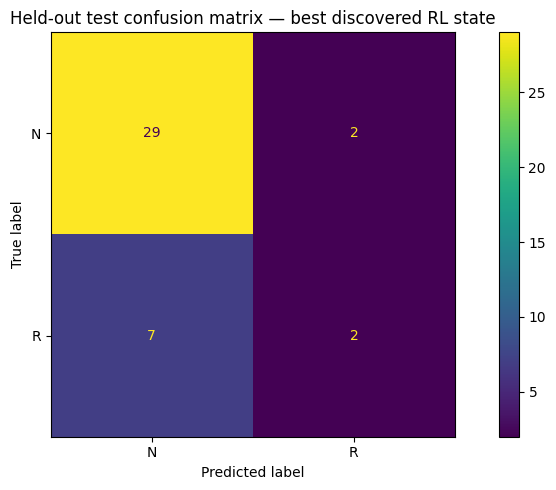

In [ ]:
rl_info = chosen["RL best discovered state"]
rl_final = make_svm()
rl_final.fit(X_trainval[rl_info["features"]], y_trainval)
rl_test_pred = rl_final.predict(X_test[rl_info["features"]])
print("Best discovered RL subset:", rl_info["features"])
print(classification_report(y_test, rl_test_pred, target_names=class_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, rl_test_pred, display_labels=class_names)
plt.title("Held-out test confusion matrix — best discovered RL state")
plt.tight_layout(); plt.show()

## 12. Multiple-Seed Robustness Check

The RL procedure is repeated using multiple random seeds to examine how sensitive the results are to randomness in the learning process.

For each seed, the experiment records the performance of the RL top-k feature-selection variant under the same fixed train, validation, and test split.

The mean and standard deviation across runs summarize the variation caused by different RL random seeds.

**Important limitation:** Because the data split remains fixed, this experiment measures sensitivity to RL randomness, not sensitivity to different train-validation-test partitions. It should not be interpreted as a complete estimate of dataset-sampling uncertainty.

A stronger robustness study would repeat the complete procedure across multiple stratified splits or use repeated nested cross-validation, if computationally feasible.

In [ ]:
# Repeat RL ranking and final evaluation for several seeds. This is still a small-data
# experiment; treat variability as informative, not definitive.
ROBUSTNESS_SEEDS = [11, 22, 33, 44, 55]
robust_rows = []
for sd in ROBUSTNESS_SEEDS:
    run = run_rl(epsilon=DEFAULT_EPSILON, episodes=25, seed=sd)
    order = list(np.argsort(np.where(run["feature_counts"] > 0, run["global_aor"], -np.inf))[::-1])
    # Select k from the validation curve for this seed's RL ranking.
    seed_curve = []
    for k in range(1, n_features+1):
        selected = [feature_names[i] for i in order[:k]]
        pred, _ = fit_predict(selected)
        seed_curve.append((k, balanced_accuracy_score(y_val, pred)))
    best_k = max(seed_curve, key=lambda z: z[1])[0]
    selected = [feature_names[i] for i in order[:best_k]]
    model = make_svm()
    model.fit(X_trainval[selected], y_trainval)
    pred = model.predict(X_test[selected])
    row = metric_row(f"seed_{sd}", y_test, pred, best_k)
    row["seed"] = sd
    robust_rows.append(row)

robust_df = pd.DataFrame(robust_rows)
display(robust_df.round(3))
print("\\nMean and standard deviation across seeds:")
display(robust_df[["accuracy", "balanced_accuracy", "recurrence_precision", "recurrence_recall", "recurrence_f1"]].agg(["mean", "std"]).round(3))

,model,n_features,accuracy,balanced_accuracy,recurrence_precision,recurrence_recall,recurrence_f1,seed
0,seed_11,1,0.775,0.5,0.0,0.0,0.0,11
1,seed_22,1,0.775,0.5,0.0,0.0,0.0,22
2,seed_33,1,0.775,0.5,0.0,0.0,0.0,33
3,seed_44,1,0.775,0.5,0.0,0.0,0.0,44
4,seed_55,1,0.775,0.5,0.0,0.0,0.0,55


\nMean and standard deviation across seeds:


,accuracy,balanced_accuracy,recurrence_precision,recurrence_recall,recurrence_f1
mean,0.775,0.5,0.0,0.0,0.0
std,0.000,0.0,0.0,0.0,0.0


## 13. Export Experimental Results

This section exports the generated feature rankings, comparison results, and other relevant experimental tables to CSV files.

Exporting the results makes it easier to inspect individual feature rankings, compare methods, prepare tables for a report, and reproduce the analysis without rerunning every experiment.

The exported results should be accompanied by the experiment's configuration, including the random seed, data split, number of episodes, learning rate, discount factor, epsilon, and excluded columns.

The exported tables contain the results produced by the notebook. They should not be interpreted as independently verified results until the notebook has completed execution successfully.

In [ ]:
aor_df.to_csv("wpbc_global_aor_ranking.csv", index=False)
performance.to_csv("wpbc_feature_count_performance.csv", index=False)
test_results.to_csv("wpbc_test_results.csv", index=False)
robust_df.to_csv("wpbc_rl_seed_robustness.csv", index=False)
rl_states_df.to_csv("wpbc_rl_visited_states_validation.csv", index=False)
sweep_df.to_csv("wpbc_epsilon_sweep.csv", index=False)

try:
    from google.colab import files
    for filename in ["wpbc_global_aor_ranking.csv", "wpbc_feature_count_performance.csv",
                     "wpbc_test_results.csv", "wpbc_rl_seed_robustness.csv", "wpbc_rl_visited_states_validation.csv", "wpbc_epsilon_sweep.csv"]:
        files.download(filename)
except Exception:
    print("CSV files saved in the current working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Discussion, Limitations, and Reporting Guidelines

The results of this experiment should be interpreted in the context of the dataset, the implementation choices, and the limitations of the original paper.

### Experimental details to report

Record the random seed, train-validation-test split, number of RL episodes, learning rate (\(\alpha\)), discount factor (\(\gamma\)), epsilon, feature exclusions, and classifier configuration.

### Evaluation beyond accuracy

WPBC has an imbalanced target distribution. A model can obtain apparently high accuracy by favoring the majority class. Therefore, the results should be compared with the majority-class baseline and should emphasize balanced accuracy and recurrence-class recall, precision, and F1-score.

### Comparing RL with baseline methods

The RL approach should not be described as superior unless the held-out test metrics support that conclusion. The best discovered validation state is subject to selection bias because many subsets are compared using the same small validation set.

The best train-CV state is evaluated separately from the validation-selected alternatives to distinguish the agent's training criterion from validation-based selection.

### Limitations of the reproduction

This is a paper-informed implementation rather than a bit-for-bit reproduction. The original paper reports WPBC accuracy of 76.29 ± 0.007%, but its description does not provide enough implementation and evaluation details to guarantee exact numerical replication.

The dataset contains a limited number of observations and features. The RL agent explores only a fraction of the possible feature subsets, so the global AOR ranking largely reflects the marginal rewards observed during that exploration. State-value estimates may also be based on relatively few revisits.

The epsilon strategy and the number of model features used here are implementation choices that may differ from the original experiment. These differences should be disclosed when comparing the results with the paper.

### Conclusion

The experiment provides a practical framework for studying reinforcement-learning-based feature selection and comparing it with conventional filter methods. Its findings should be presented as results for the specified dataset and evaluation protocol, not as proof that RL is universally better or that the selected features are clinically meaningful.
